# Lecture 6: CNN and U-Net Architectures for Spatial Fields

SmallCNN, our model since Lecture 1, has four 3 × 3 convolutions, so each output cell depends on a 9 × 9 block of input cells: its **receptive field**.
On a fine grid that block is a small part of one bubble. We compute receptive fields, build a U-Net, and compare it with SmallCNN on BubbleML.

Four parts:

1. Compute receptive fields with the rule $r_\ell = r_{\ell-1} + (k_\ell - 1)\, j_{\ell-1}$, $j_\ell = j_{\ell-1} s_\ell$, and check them by backpropagation.
2. Build the U-Net from the lecture figure.
3. Train SmallCNN and the U-Net on BubbleML at 128 × 128; compare one-step error and energy spectra.
4. Remove the skip connections and compare again.

In [1]:
import os
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Using device:", device)

torch.manual_seed(0)
rng = np.random.default_rng(0)
DATA_DIR = "../data/bubbleml"
FILE = "bubbleml2_Twall106_128.npz"
URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/bubbleml/"
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(os.path.join(DATA_DIR, FILE)):
    print("downloading", FILE)
    urllib.request.urlretrieve(URL + FILE, os.path.join(DATA_DIR, FILE))

# temperature colormap from Lecture 1 (https://github.com/therml-ai/boiling-viz), for theta in [0, 1]
temp_cmap = LinearSegmentedColormap.from_list("temp_green", list(zip(
    [0.0, 0.02, 0.04, 0.06, 0.08, 0.1, 0.134, 0.167, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    ["#0000FF", "#0443FF", "#0E7AFF", "#16B4FF", "#1FF1FF", "#21FFD3", "#22FF9B", "#22FF67", "#22FF15", "#29FF06",
     "#45FF07", "#6DFF08", "#9EFF09", "#D4FF0A", "#FEF30A", "#FEB709", "#FD7D08", "#FC4908", "#FC1407", "#FB0007"])))

Using device: mps


### The data

BubbleML_2, subcooled pool boiling of FC-72 with a 106 °C heater, averaged from 512 × 512 to 128 × 128 (cell size 0.125 length units).
Frames are 0.2 nondimensional time units apart, from $t = 40$ to $t = 200$. Three input channels: temperature $\theta = (T - 50\,°\mathrm{C})/(106\,°\mathrm{C} - 50\,°\mathrm{C})$
and the velocity components $u, v$. The target is the change in $\theta$ over one frame interval.

We split in time: the first 600 frames ($t$ from 40 to 160) for training, the rest ($t$ from 160 to 200) for testing.
As in Lecture 4, the input channels are standardized and the network predicts the standardized increment:
$\hat\theta_{n+1} = \theta_n + \mu_\Delta + \sigma_\Delta\, f(\tilde x_n)$.

train: (600, 3, 128, 128)   test: (201, 3, 128, 128)


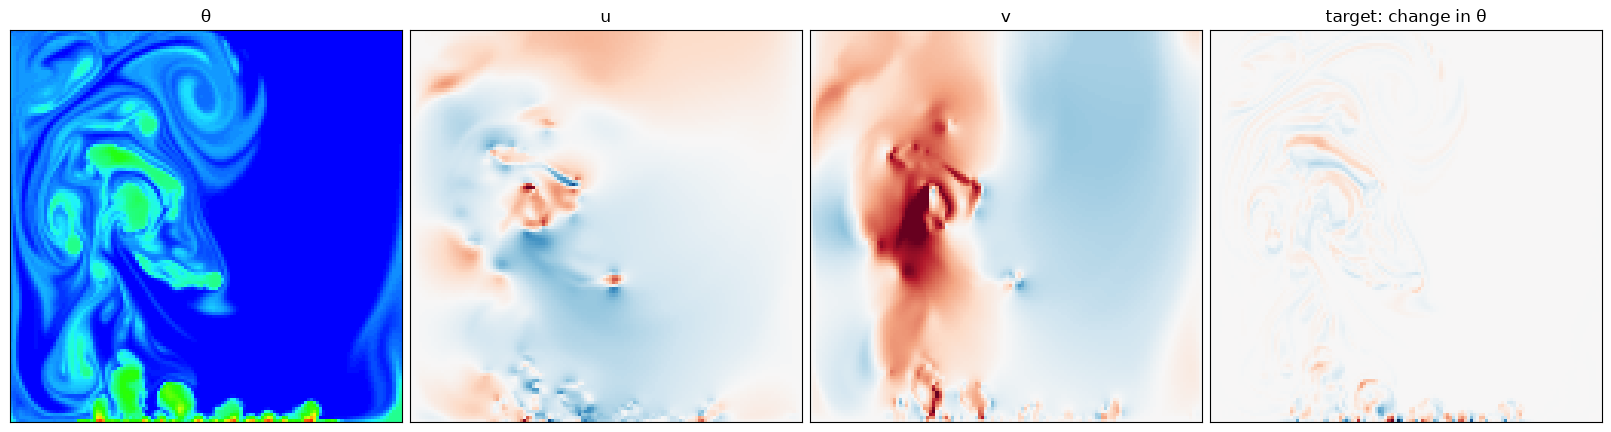

In [2]:
d = np.load(os.path.join(DATA_DIR, FILE))
data = np.stack([d["temperature"], d["velx"], d["vely"]], axis=1).astype(np.float32)   # [frames, 3, 128, 128]
N_TRAIN = 600
train_np, test_np = data[:N_TRAIN], data[N_TRAIN:]
print("train:", train_np.shape, "  test:", test_np.shape)

def increment_stats(x):
    du = x[1:, 0] - x[:-1, 0]
    return dict(mu=x.mean(axis=(0, 2, 3)), sd=x.std(axis=(0, 2, 3)), mu_du=float(du.mean()), sd_du=float(du.std()))

stats = increment_stats(train_np)
train_x, train_y = torch.from_numpy(train_np[:-1]), torch.from_numpy(train_np[1:, :1])
test_x, test_y = torch.from_numpy(test_np[:-1]), torch.from_numpy(test_np[1:, :1])

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), layout="constrained")
axes[0].imshow(test_np[0, 0], cmap=temp_cmap, vmin=0, vmax=1, origin="lower"); axes[0].set_title("θ")
axes[1].imshow(test_np[0, 1], cmap="RdBu_r", vmin=-3, vmax=3, origin="lower"); axes[1].set_title("u")
axes[2].imshow(test_np[0, 2], cmap="RdBu_r", vmin=-3, vmax=3, origin="lower"); axes[2].set_title("v")
change = test_np[1, 0] - test_np[0, 0]; v = np.abs(change).max()
axes[3].imshow(change, cmap="RdBu_r", vmin=-v, vmax=v, origin="lower"); axes[3].set_title("target: change in θ")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.show()

---
## Part 1: Receptive fields

Go through the layers from the input and track two numbers, starting at $r_0 = j_0 = 1$:
$r$, the receptive field in input cells, and $j$, the spacing between neighboring outputs in input cells.
A layer with kernel size $k$ and stride $s$ does

$$r \leftarrow r + (k - 1)\, j, \qquad j \leftarrow j\, s .$$

Pooling is a layer with $k = 2$, $s = 2$. A dilated kernel spans $d(k-1) + 1$ cells; use that in place of $k$.

In [3]:
def receptive_field(layers):
    # layers: list of (k, s); returns r after each layer
    r, j, out = 1, 1, []
    for k, s in layers:
        r += (k - 1) * j
        j *= s
        out.append(r)
    return out

smallcnn_layers = [(3, 1)] * 4
stride2_layers = [(3, 1), (3, 2), (3, 1)]                             # lecture example: stride 2 in the second layer
unet_encoder_layers = [(3, 1), (3, 1), (2, 2)] * 3 + [(3, 1), (3, 1)]  # 3 levels + bottleneck

print("SmallCNN:          ", receptive_field(smallcnn_layers))
print("Stride-2 example: ", receptive_field(stride2_layers))
print("U-Net encoder:     ", receptive_field(unet_encoder_layers))
print("8 stride-1 convs:  ", receptive_field([(3, 1)] * 8)[-1])

SmallCNN:           [3, 5, 7, 9]
Stride-2 example:  [3, 5, 9]
U-Net encoder:      [3, 5, 6, 10, 14, 16, 24, 32, 36, 52, 68]
8 stride-1 convs:   17


**Check by backpropagation.** For generic weights, the gradient of one output cell with respect to the input is nonzero exactly on the receptive field.
We take an untrained network, backpropagate from the center output cell, and measure the width of the nonzero region.
We use float64 so that small gradients at the edge of the receptive field are not rounded to zero.

In [4]:
def measured_rf(net, n=160, cin=1):
    net = net.double()
    x = torch.randn(1, cin, n, n, dtype=torch.float64, requires_grad=True)
    out = net(x)
    c = out.shape[-1] // 2
    out[0, 0, c, c].backward()
    nz = (x.grad[0].abs().sum(0) > 0).numpy()
    rows, cols = np.where(nz)
    return rows.max() - rows.min() + 1, cols.max() - cols.min() + 1

def smallcnn_body(cin=1, hidden=32):
    c = lambda i, o: nn.Conv2d(i, o, 3, padding=1)
    return nn.Sequential(c(cin, hidden), nn.GELU(), c(hidden, hidden), nn.GELU(), c(hidden, hidden), nn.GELU(), c(hidden, 1))

def encoder_without_norm(cin=1, ch=(16, 32, 64, 128)):
    layers, i = [], cin
    for level, o in enumerate(ch):
        layers += [nn.Conv2d(i, o, 3, padding=1), nn.GELU(), nn.Conv2d(o, o, 3, padding=1), nn.GELU()]
        if level < 3:
            layers.append(nn.AvgPool2d(2))
        i = o
    return nn.Sequential(*layers)

print("SmallCNN, measured:      ", measured_rf(smallcnn_body()))
print("U-Net encoder, measured: ", measured_rf(encoder_without_norm()))

SmallCNN, measured:       (np.int64(9), np.int64(9))
U-Net encoder, measured:  (np.int64(68), np.int64(68))


**What to observe**

* The measured widths match the rule: 9 for SmallCNN and 68 for the U-Net encoder (in the measurement, the output cell sits on the 16 × 16 bottleneck grid).
* The encoder reaches 68 cells with 8 convolutions and 3 poolings; the same 8 convolutions with stride 1 reach 17.
* We left out group normalization here. It divides by the mean and variance over the whole field, so in the full U-Net every input cell
  affects every output a little. The rule counts the convolutions and pooling, which is where the local dependence comes from.

---
## Part 2: The U-Net

Each block is a 3 × 3 convolution, group normalization and GELU, twice. Three encoder levels with 2 × 2 average pooling between them,
a bottleneck at 16 × 16 with 128 channels, and a decoder that upsamples bilinearly, applies a 3 × 3 convolution,
and concatenates the encoder activations of the same size (the skip connection). A 1 × 1 convolution maps 16 channels to the output.
With `skips=False` the same class gives the encoder–decoder.

In [5]:
def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.GroupNorm(8, o), nn.GELU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.GroupNorm(8, o), nn.GELU())

class UNet(nn.Module):
    def __init__(self, cin=3, ch=(16, 32, 64, 128), skips=True):
        super().__init__()
        self.skips = skips
        self.enc = nn.ModuleList([block(cin, ch[0]), block(ch[0], ch[1]), block(ch[1], ch[2])])
        self.mid = block(ch[2], ch[3])
        self.up = nn.ModuleList([nn.Conv2d(ch[3], ch[2], 3, padding=1),
                                 nn.Conv2d(ch[2], ch[1], 3, padding=1),
                                 nn.Conv2d(ch[1], ch[0], 3, padding=1)])
        m = 2 if skips else 1                       # concatenation doubles the decoder's input channels
        self.dec = nn.ModuleList([block(m * ch[2], ch[2]), block(m * ch[1], ch[1]), block(m * ch[0], ch[0])])
        self.out = nn.Conv2d(ch[0], 1, 1)           # 1 x 1 convolution

    def forward(self, x):
        hs = []
        for e in self.enc:
            x = e(x); hs.append(x); x = F.avg_pool2d(x, 2)
        x = self.mid(x)
        for up, dec, h in zip(self.up, self.dec, reversed(hs)):
            x = up(F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False))
            if self.skips:
                x = torch.cat([x, h], dim=1)
            x = dec(x)
        return self.out(x)

class Surrogate(nn.Module):
    # standardized inputs; the network predicts the standardized change in theta
    def __init__(self, net, st):
        super().__init__()
        self.net = net
        self.register_buffer("mu", torch.tensor(st["mu"]).view(1, 3, 1, 1))
        self.register_buffer("sd", torch.tensor(st["sd"]).view(1, 3, 1, 1))
        self.mu_du, self.sd_du = st["mu_du"], st["sd_du"]

    def increment(self, x):
        return self.net((x - self.mu) / self.sd)

    def forward(self, x):
        return x[:, :1] + self.mu_du + self.sd_du * self.increment(x)

def count(m):
    return sum(p.numel() for p in m.parameters())

for name, net in [("SmallCNN", smallcnn_body(cin=3)), ("encoder-decoder", UNet(skips=False)), ("U-Net", UNet())]:
    y = net(torch.zeros(2, 3, 128, 128))
    print(f"{name:16s} parameters {count(net):8,d}   output {tuple(y.shape)}")

SmallCNN         parameters   19,681   output (2, 1, 128, 128)
encoder-decoder  parameters  488,817   output (2, 1, 128, 128)
U-Net            parameters  537,201   output (2, 1, 128, 128)


---
## Part 3: SmallCNN and U-Net on BubbleML

Same training for every model: MSE on the standardized increment, Adam (lr $10^{-3}$, cosine decay), batch 16, `STEPS` steps.

In [6]:
STEPS = 800

def train(net, steps=STEPS, batch=16, seed=0):
    torch.manual_seed(seed); g = np.random.default_rng(seed)
    model = Surrogate(net, stats).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    t0 = time.time()
    for step in range(steps):
        i = g.integers(0, len(train_x), batch)
        x, y = train_x[i].to(device), train_y[i].to(device)
        target = (y - x[:, :1] - stats["mu_du"]) / stats["sd_du"]
        loss = F.mse_loss(model.increment(x), target)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if step % 200 == 0:
            print(f"  step {step:4d}  loss {loss.item():.3f}  ({time.time() - t0:.0f} s)")
    return model.eval()

@torch.no_grad()
def predicted_change(model, x=test_x):
    out = [(model(x[i:i + 32].to(device)) - x[i:i + 32, :1].to(device)).cpu() for i in range(0, len(x), 32)]
    return torch.cat(out)[:, 0].numpy()

true_change = (test_y - test_x[:, :1])[:, 0].numpy()

def relative_error(pred, true=true_change):
    return np.linalg.norm(pred - true) / np.linalg.norm(true)

models = {}
print("SmallCNN"); models["SmallCNN"] = train(smallcnn_body(cin=3))
print("U-Net");    models["U-Net"] = train(UNet())
preds = {name: predicted_change(m) for name, m in models.items()}
for name, p in preds.items():
    print(f"{name:10s} one-step relative error of the change in θ: {relative_error(p):.3f}")

SmallCNN
  step    0  loss 0.982  (1 s)
  step  200  loss 0.288  (8 s)
  step  400  loss 0.273  (14 s)
  step  600  loss 0.269  (21 s)
U-Net
  step    0  loss 1.102  (1 s)
  step  200  loss 0.226  (23 s)
  step  400  loss 0.199  (46 s)
  step  600  loss 0.180  (68 s)
SmallCNN   one-step relative error of the change in θ: 0.521
U-Net      one-step relative error of the change in θ: 0.466


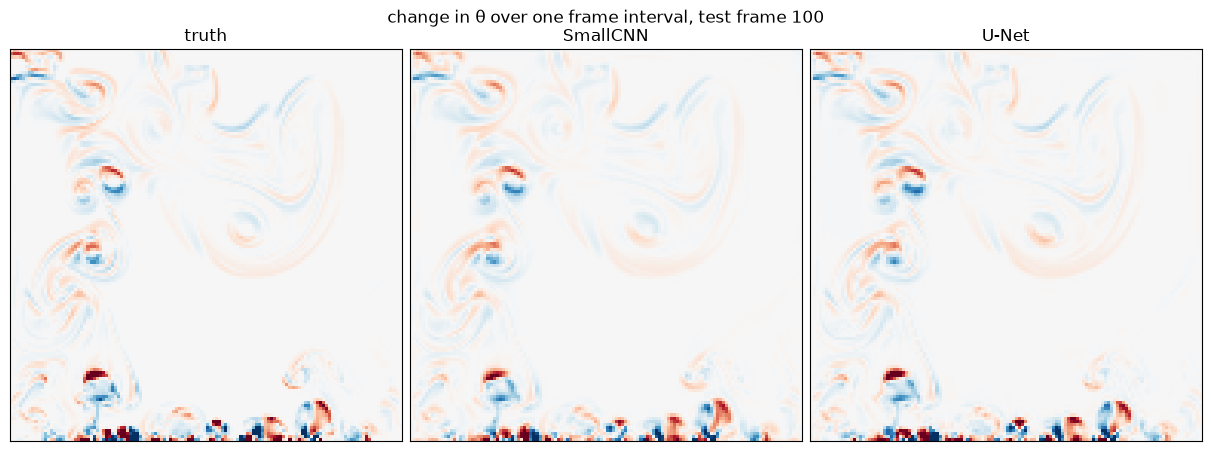

In [7]:
def show(preds, i=100):
    names = ["truth"] + list(preds)
    fig, axes = plt.subplots(1, len(names), figsize=(4 * len(names), 4.4), layout="constrained")
    v = np.percentile(np.abs(true_change), 99.5)
    for ax, name in zip(axes, names):
        img = true_change[i] if name == "truth" else preds[name][i]
        ax.imshow(img, cmap="RdBu_r", vmin=-v, vmax=v, origin="lower")
        ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"change in θ over one frame interval, test frame {i}")
    plt.show()

show(preds)

**Energy spectrum.** Write the field as a sum of Fourier modes and sum $|\hat u|^2$ over all modes with the same $|k|$ (Lecture 3).
$k$ is in cycles per domain width; large scale = long wavelength = low $k$.

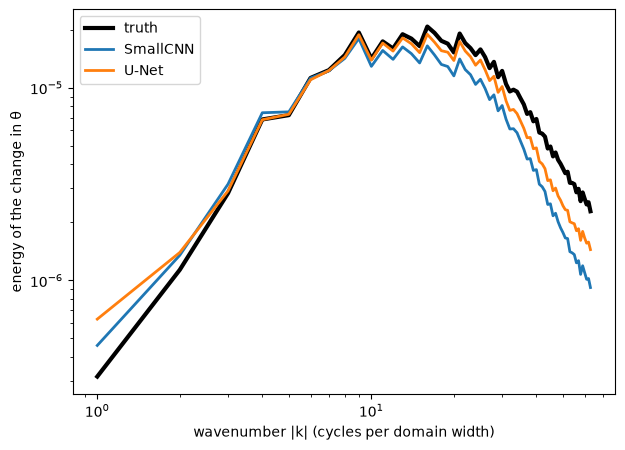

In [8]:
def radial_spectrum(fields):
    n = fields.shape[-1]
    U = np.fft.fft2(fields - fields.mean(axis=(-2, -1), keepdims=True)) / n**2
    P = (np.abs(U) ** 2).mean(axis=0)
    k = np.fft.fftfreq(n) * n
    kk = np.sqrt(k[:, None] ** 2 + k[None, :] ** 2)
    E = np.array([P[(kk >= a - 0.5) & (kk < a + 0.5)].sum() for a in range(1, n // 2)])
    return np.arange(1, n // 2), E

def plot_spectra(preds):
    k, E = radial_spectrum(true_change)
    plt.figure(figsize=(7, 5))
    plt.loglog(k, E, "k", lw=3, label="truth")
    for name, p in preds.items():
        plt.loglog(*radial_spectrum(p), lw=2, label=name)
    plt.xlabel("wavenumber |k| (cycles per domain width)"); plt.ylabel("energy of the change in θ")
    plt.legend(); plt.show()

plot_spectra(preds)

**What to observe**

* The one-step errors are close. SmallCNN sees 4 cells in each direction. On this grid, 99% of the cells move at most 4 cells per frame; the fastest fluid, about half of it in or next to bubbles, moves up to about 16.
* The U-Net reaches a much lower training loss than its test error suggests: 27 times more parameters, and 600 training frames from one simulation.
* In the spectrum, both models match the truth at large scales and have too little energy at small scales (spectral bias).
* The exact numbers change with `STEPS` and the seed. Check which trends stay the same with `seed=1`.

---
## Part 4: Remove the skip connections

Before running the next cell, predict: what happens to the error and to the spectrum without the skip connections?

encoder-decoder
  step    0  loss 1.036  (0 s)
  step  200  loss 0.679  (13 s)
  step  400  loss 0.594  (27 s)
  step  600  loss 0.510  (40 s)
SmallCNN         one-step relative error: 0.521
U-Net            one-step relative error: 0.466
encoder-decoder  one-step relative error: 0.784


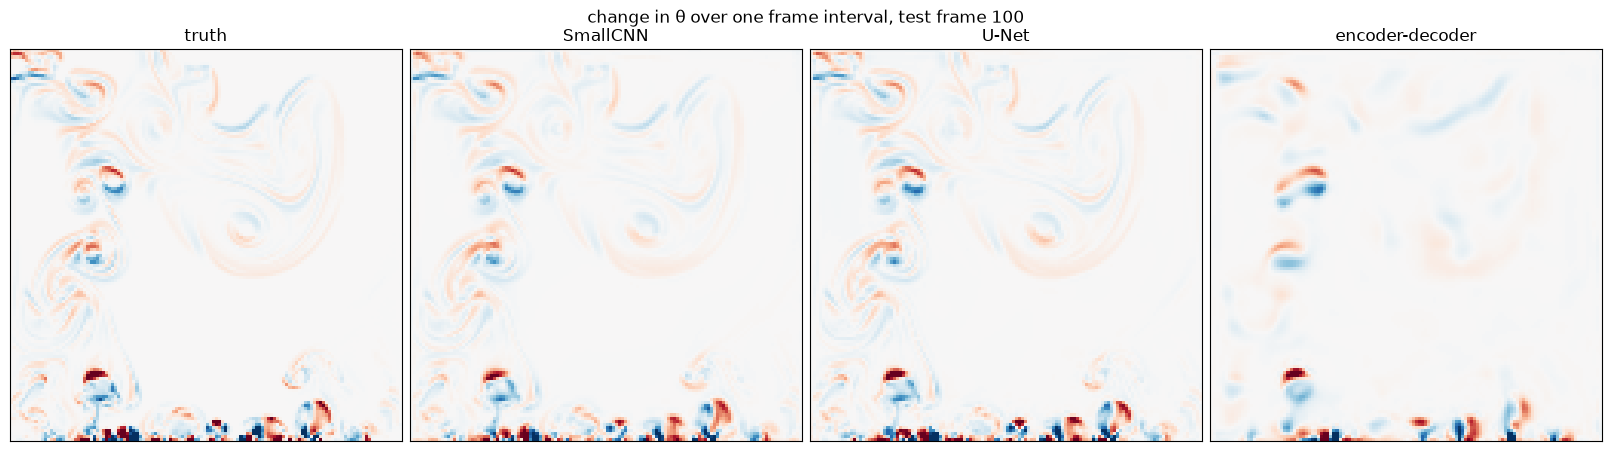

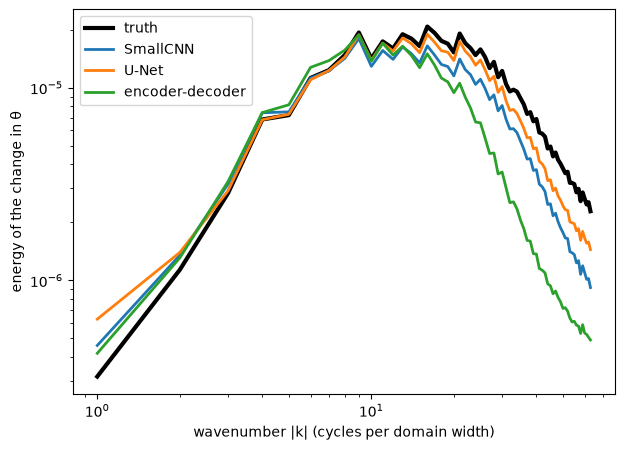

In [9]:
print("encoder-decoder"); models["encoder-decoder"] = train(UNet(skips=False))
preds["encoder-decoder"] = predicted_change(models["encoder-decoder"])
for name, p in preds.items():
    print(f"{name:16s} one-step relative error: {relative_error(p):.3f}")
show(preds)
plot_spectra(preds)

**What to observe**

* Without skips, the interfaces are blurred: every value in the output passes through the 16 × 16 bottleneck.
* The encoder–decoder's spectrum falls below the U-Net's at small scales. The skip connections restore what the bottleneck loses.
* A blurred prediction can still have a moderate mean squared error, because it gets the large, energetic structures right. 

---
## Exercises

1. **Dilation.** Build a SmallCNN with dilations 1, 2, 4, 8 (`nn.Conv2d(..., dilation=d, padding=d)`). Compute its receptive field with `receptive_field`
   (use $k_{\text{eff}} = d(k-1)+1$), check it with `measured_rf`, then train it and compare its error and spectrum with SmallCNN. It has the same number of weights.
2. **Resolution.** Average the data to 64 × 64 (`F.avg_pool2d` on the frames), train SmallCNN there, and test the trained model on the 128 × 128 test frames.
   Compare with the model trained at 128 × 128. Explain the result using the finite-difference stencils from Lecture 3.
3. **Checkerboards.** Apply `nn.ConvTranspose1d(1, 1, kernel_size=3, stride=2, bias=False)` with all weights set to 1 to an input of ones of length 8.
   Which output cells get double weight? Repeat for kernel sizes 2 and 4. Which kernel sizes give a constant output away from the ends, and why?

In [10]:
# Exercise 1 starter
def dilated_smallcnn(cin=3, hidden=32, dilations=(1, 2, 4, 8)):
    # TODO: four 3 x 3 convolutions with the given dilations; keep the grid size (padding = dilation); GELU between layers
    raise NotImplementedError

# print(receptive_field([(2 * d + 1, 1) for d in (1, 2, 4, 8)]))   # k_eff = d (k - 1) + 1 with k = 3
# print(measured_rf(dilated_smallcnn(cin=1)))